# Residual ensemble instead of a parallel one

The final pipeline runs the LSTM and XGBoost side by side and blends their forecasts with
inverse-RMSE weights. This notebook tries the other common way of combining two models: run the
LSTM first, then train XGBoost on what the LSTM got wrong, and add the two together.

Everything except the ensemble structure is held identical to `LSTM_XGB_Prefinal.ipynb`, so the
comparison is clean:

- the same CSV and the same cleaning
- the same Box-Cox lambda and the same fitted scaler, both loaded rather than refitted
- the same 9058-day split and the same 70-day window
- the same LSTM, loaded from cache and never retrained
- the same XGBoost settings

This is a quick test of an idea, not a tuned model. Nothing is searched or optimised here. The
question is only what the structure does to RMSE, which is what the study is judged on.

In [1]:
# the notebook expects the repo root (2619492.csv, models/) as the working directory
import os
from pathlib import Path

start = Path.cwd()
for cand in [start, *start.parents]:
    if (cand / "2619492.csv").exists() and (cand / "streamlit_dashboard").is_dir():
        os.chdir(cand)
        break
else:
    raise RuntimeError(f"could not find repo root starting from {start}")

print(f"working directory: {Path.cwd()}")

working directory: C:\Users\Dell\Desktop\Thesis


In [2]:
import math
import json
import time
import hashlib
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from scipy.stats import boxcox, pearsonr
from scipy.special import inv_boxcox
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import xgboost as xgb
import tensorflow as tf

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

print(f"xgboost {xgb.__version__}, tensorflow {tf.__version__}")

xgboost 3.4.1, tensorflow 2.21.0


In [3]:
# helpers, same definitions as LSTM_XGB_Prefinal.ipynb
def inv_boxcox1p(bcdata, bclambda):
    return inv_boxcox(bcdata, bclambda) - 1


def split_sequences(series, window):
    x, y = [], []
    for i in range(len(series)):
        end = i + window
        if end > len(series) - 1:
            break
        x.append(series[i:end])
        y.append(series[end])
    return np.array(x), np.array(y)


def safe_mape(y_true, y_pred, min_actual=0.1):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mask = y_true >= min_actual
    if mask.sum() == 0:
        return float('nan'), 0
    return float(np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100.0), int(mask.sum())


def compute_sample_weights(y_boxcox, lambda_value, floor=0.01):
    y_orig = np.maximum(inv_boxcox1p(np.asarray(y_boxcox, dtype=float), lambda_value), 0.0)
    return np.sqrt(y_orig + floor)


RAIN_INTENSITY_BINS = [-np.inf, 1e-9, 0.2, 0.5, np.inf]
RAIN_INTENSITY_LABELS = ['No Rain (0 in)', 'Light (0-0.2 in)',
                         'Moderate (0.2-0.5 in)', 'Heavy (>0.5 in)']


def rainfall_intensity_performance(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    buckets = np.asarray(pd.cut(y_true, bins=RAIN_INTENSITY_BINS, labels=RAIN_INTENSITY_LABELS))
    rows = []
    for label in RAIN_INTENSITY_LABELS:
        mask = (buckets == label)
        n = int(mask.sum())
        if n == 0:
            rows.append({'Intensity': label, 'N': 0, 'RMSE': float('nan'), 'MAE': float('nan')})
            continue
        rows.append({'Intensity': label, 'N': n,
                     'RMSE': math.sqrt(mean_squared_error(y_true[mask], y_pred[mask])),
                     'MAE': mean_absolute_error(y_true[mask], y_pred[mask])})
    return pd.DataFrame(rows)


def evaluate_all(y_true, y_pred, label):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    rmse = math.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    mape, mape_n = safe_mape(y_true, y_pred)
    return {'label': label, 'rmse': rmse, 'mae': mae, 'mape': mape, 'mape_n': mape_n,
            'r2': r2_score(y_true, y_pred),
            'bias': float(np.mean(y_pred - y_true)),
            'pred_sd': float(np.std(y_pred))}


def sha256_dir(path):
    path = Path(path)
    if not path.is_dir():
        return {}
    out = {}
    for f in sorted(path.rglob('*')):
        if f.is_file():
            out[str(f.relative_to(path))] = hashlib.sha256(f.read_bytes()).hexdigest()[:16]
    return out


print("helpers defined")

helpers defined


In [4]:
DATA_CUTOFF = 9058
TOTAL_DATA_LENGTH = 10988
WINDOW_SIZE = 70
XGB_VAL_FRACTION = 0.12
XGB_EARLY_STOPPING_ROUNDS = 60

BASELINE_RMSE = 6.2009          # reproduced here
BASELINE_RMSE_STATED = 6.181    # as stated in the baseline study
TARGET_RMSE = 5.56              # 10% below the stated baseline

PREFINAL_DIR = Path("models") / "v2_prefinal"   # read only
STATIC_DIR = Path("models") / "v2_static"       # read only
MODEL_DIR = Path("models") / "v2_residual_chain"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

print(f"reading from {PREFINAL_DIR}, writing to {MODEL_DIR}")

reading from models\v2_prefinal, writing to models\v2_residual_chain


In [5]:
# both of these are referenced by the thesis and the website, so hash them now and
# re-check at the end
HASHES_ON_ENTRY = {
    str(STATIC_DIR): sha256_dir(STATIC_DIR),
    str(PREFINAL_DIR): sha256_dir(PREFINAL_DIR),
}
for name, h in HASHES_ON_ENTRY.items():
    print(f"hashed {len(h)} files in {name}")

hashed 4 files in models\v2_static
hashed 19 files in models\v2_prefinal


In [6]:
# preprocessing, identical to the parallel run. The lambda is recomputed the same way and
# checked against the saved one, and the scaler is loaded rather than refitted.
prefinal_meta = json.loads((PREFINAL_DIR / "metadata.json").read_text(encoding="utf-8"))
saved_lambda = prefinal_meta["preprocessing"]["box_cox_lambda"]

rainfall = pd.read_csv("2619492.csv")
rainfall["DATE"] = pd.to_datetime(rainfall["DATE"], dayfirst=True)
rainfall = rainfall.set_index("DATE")
print(f"loaded {len(rainfall)} records")

lam_value = boxcox(rainfall.PRCP.iloc[:DATA_CUTOFF] + 1)[1]
assert abs(lam_value - saved_lambda) < 1e-12, "lambda differs from the parallel run"
print(f"box-cox lambda {lam_value:.12f}, matches the parallel run")

inv_data = boxcox(rainfall.PRCP.to_numpy(dtype=float) + 1, lmbda=lam_value)
scaler = joblib.load(PREFINAL_DIR / "scaler.joblib")
rain_data_scaled = scaler.transform(inv_data.reshape(-1, 1))[:, 0]

lstm_series = rain_data_scaled[:TOTAL_DATA_LENGTH]
xgb_series = inv_data[:TOTAL_DATA_LENGTH]

BC_UPPER = -1.0 / lam_value


def to_original(bc_values):
    bc = np.asarray(bc_values, dtype=float).reshape(-1)
    n_clipped = int(np.sum(bc >= BC_UPPER))
    return inv_boxcox1p(np.minimum(bc, BC_UPPER - 1e-9), lam_value), n_clipped


print(f"inverse-transform upper limit {BC_UPPER:.6f}")

loaded 11323 records
box-cox lambda -1.438691568238, matches the parallel run


inverse-transform upper limit 0.695076


In [7]:
# same split and windowing as the parallel run
lstm_train_series, lstm_test_series = lstm_series[:DATA_CUTOFF], lstm_series[DATA_CUTOFF:]
xgb_train_series, xgb_test_series = xgb_series[:DATA_CUTOFF], xgb_series[DATA_CUTOFF:]

x_train, y_train = split_sequences(lstm_train_series, WINDOW_SIZE)
x_test, y_test = split_sequences(lstm_test_series, WINDOW_SIZE)
x_train = x_train.reshape(-1, WINDOW_SIZE, 1)
x_test = x_test.reshape(-1, WINDOW_SIZE, 1)

x_train_lag, y_train_lag = split_sequences(xgb_train_series, WINDOW_SIZE)
x_test_lag, y_test_lag = split_sequences(xgb_test_series, WINDOW_SIZE)

y_test_orig, _ = to_original(y_test_lag)
print(f"train windows {x_train.shape}, test windows {x_test.shape}")
print(f"scored test days {len(y_test_orig)}")

train windows (8988, 70, 1), test windows (1860, 70, 1)
scored test days 1860


In [8]:
# the frozen LSTM, loaded not trained
lstm_model = tf.keras.models.load_model(PREFINAL_DIR / "lstm_model.keras")
print(f"loaded cached LSTM ({lstm_model.count_params():,} parameters), no training here")

t0 = time.time()
lstm_train_bc = scaler.inverse_transform(
    lstm_model.predict(x_train, verbose=0).reshape(-1, 1))[:, 0]
lstm_test_bc = scaler.inverse_transform(
    lstm_model.predict(x_test, verbose=0).reshape(-1, 1))[:, 0]
print(f"LSTM predictions in {time.time() - t0:.1f}s")

lstm_test_orig, _ = to_original(lstm_test_bc)

# consistency check against the parallel run's saved predictions
saved = np.load(PREFINAL_DIR / "predictions.npz")
gap = float(np.max(np.abs(saved["lstm_1day"] - lstm_test_orig)))
print(f"largest difference from the parallel run's saved LSTM predictions: {gap:.2e} in")
assert gap < 1e-6, "LSTM predictions do not match the parallel run"

loaded cached LSTM (13,217 parameters), no training here


LSTM predictions in 4.1s
largest difference from the parallel run's saved LSTM predictions: 0.00e+00 in


In [9]:
# the residuals XGBoost will be asked to learn, in box-cox space
resid_train_bc = y_train_lag - lstm_train_bc
resid_test_bc = y_test_lag - lstm_test_bc

y_train_orig, _ = to_original(y_train_lag)
lstm_train_orig, _ = to_original(lstm_train_bc)

print("How much is left for XGBoost to learn?")
print(f"  observed spread, train      {y_train_orig.std():.4f} in")
print(f"  LSTM forecast spread, train {lstm_train_orig.std():.4f} in "
      f"({lstm_train_orig.std() / y_train_orig.std() * 100:.2f}% of observed)")
print(f"  observed spread, test       {y_test_orig.std():.4f} in")
print(f"  LSTM forecast spread, test  {lstm_test_orig.std():.4f} in "
      f"({lstm_test_orig.std() / y_test_orig.std() * 100:.2f}% of observed)")

r_orig = y_train_orig - lstm_train_orig
corr_resid = pearsonr(r_orig, y_train_orig)[0]
print(f"\n  corr(residual, observed) on train  {corr_resid:.6f}")
print(f"  sd(residual) / sd(observed)        {r_orig.std() / y_train_orig.std():.6f}")
print("\n  A correlation near 1 means the residual is almost the original series again, so")
print("  XGBoost would be relearning the same target it already learns.")

How much is left for XGBoost to learn?
  observed spread, train      5.2798 in
  LSTM forecast spread, train 0.0066 in (0.13% of observed)
  observed spread, test       5.5397 in
  LSTM forecast spread, test  0.0065 in (0.12% of observed)

  corr(residual, observed) on train  0.999999
  sd(residual) / sd(observed)        0.999985

  A correlation near 1 means the residual is almost the original series again, so
  XGBoost would be relearning the same target it already learns.


In [10]:
# XGBoost on the residuals, same settings as the parallel run so only the structure differs
search = json.loads((PREFINAL_DIR / "search_result.json").read_text(encoding="utf-8"))
params = dict(search["selected"])
params.update(search["fit_strategy"])
params.update(search["objective"])
params.update(eval_metric="rmse", random_state=RANDOM_STATE, n_jobs=-1, verbosity=0,
              early_stopping_rounds=XGB_EARLY_STOPPING_ROUNDS)
print("XGBoost settings reused from the parallel run:")
print(f"  {search['fit_strategy']}")
print(f"  {search['objective']}")

n_val = max(256, int(len(x_train_lag) * XGB_VAL_FRACTION))
x_tr, x_val = x_train_lag[:-n_val], x_train_lag[-n_val:]
r_tr, r_val = resid_train_bc[:-n_val], resid_train_bc[-n_val:]

# weights come from the actual rainfall on each day, not from the residual, so heavy days
# still carry more weight exactly as they do in the parallel run
sw_tr = compute_sample_weights(y_train_lag[:-n_val], lam_value)
sw_val = compute_sample_weights(y_train_lag[-n_val:], lam_value)

chain_model = xgb.XGBRegressor(**params)
t0 = time.time()
chain_model.fit(x_tr, r_tr, sample_weight=sw_tr, eval_set=[(x_val, r_val)],
                sample_weight_eval_set=[sw_val], verbose=False)
chain_fit_seconds = time.time() - t0
best_it = getattr(chain_model, "best_iteration", None)
trees_used = int(best_it + 1) if best_it is not None else params["n_estimators"]
print(f"\nfitted on residuals in {chain_fit_seconds:.1f}s ({trees_used} trees used)")

XGBoost settings reused from the parallel run:
  {'booster': 'dart', 'tree_method': 'hist', 'rate_drop': 0.1, 'skip_drop': 0.5}
  {'objective': 'reg:quantileerror', 'quantile_alpha': 0.5}



fitted on residuals in 138.9s (1488 trees used)


In [11]:
# the chain forecast: LSTM output plus XGBoost's correction, inverse transformed once
chain_pred_bc = lstm_test_bc + chain_model.predict(x_test_lag)
chain_pred_orig, n_clipped = to_original(chain_pred_bc)
print(f"predictions clipped at the box-cox upper limit: {n_clipped} of {len(chain_pred_bc)}")

# the parallel run's results, loaded so nothing is refitted
xgb_alone_orig = saved["xgb_1day"]
parallel_orig = saved["ensemble_1day"]

chain_eval = evaluate_all(y_test_orig, chain_pred_orig, "Residual chain")
lstm_eval = evaluate_all(y_test_orig, lstm_test_orig, "LSTM alone")
xgb_eval = evaluate_all(y_test_orig, xgb_alone_orig, "XGBoost alone")
par_eval = evaluate_all(y_test_orig, parallel_orig, "Parallel ensemble")
const_eval = evaluate_all(y_test_orig,
                          np.full_like(y_test_orig, float(np.mean(y_train_orig))),
                          "Constant at the training mean")
print("evaluated")

predictions clipped at the box-cox upper limit: 0 of 1860
evaluated


In [12]:
# results, RMSE first because that is what the objective is written around
rows = [{'Model': 'Baseline (stated in the study)', 'RMSE': BASELINE_RMSE_STATED,
         'MAE': float('nan'), 'MAPE (%)': float('nan'), 'R2': float('nan'),
         'Bias': float('nan'), 'Forecast sd': float('nan')},
        {'Model': 'Baseline (reproduced)', 'RMSE': BASELINE_RMSE, 'MAE': 2.3244,
         'MAPE (%)': 81.10, 'R2': float('nan'), 'Bias': float('nan'),
         'Forecast sd': float('nan')}]
for e in (lstm_eval, xgb_eval, par_eval, chain_eval, const_eval):
    rows.append({'Model': e['label'], 'RMSE': e['rmse'], 'MAE': e['mae'],
                 'MAPE (%)': e['mape'], 'R2': e['r2'], 'Bias': e['bias'],
                 'Forecast sd': e['pred_sd']})
df_results = pd.DataFrame(rows)
df_results['RMSE reduction (%)'] = (BASELINE_RMSE_STATED - df_results['RMSE']) / BASELINE_RMSE_STATED * 100
df_results['Meets 5.56 target'] = np.where(df_results['RMSE'] <= TARGET_RMSE, 'yes', 'no')

print(f"One-day-ahead results on {len(y_test_orig)} scored test days\n")
print(df_results.to_string(index=False, float_format=lambda v: f'{v:.4f}'))

print(f"\nResidual chain RMSE {chain_eval['rmse']:.4f} in")
print(f"  vs parallel ensemble {par_eval['rmse']:.4f}  -> {par_eval['rmse'] - chain_eval['rmse']:+.4f}")
print(f"  vs XGBoost alone     {xgb_eval['rmse']:.4f}  -> {xgb_eval['rmse'] - chain_eval['rmse']:+.4f}")
print(f"  vs stated baseline   {BASELINE_RMSE_STATED:.4f}  -> "
      f"{(BASELINE_RMSE_STATED - chain_eval['rmse']) / BASELINE_RMSE_STATED * 100:.2f}% reduction")

One-day-ahead results on 1860 scored test days

                         Model   RMSE    MAE  MAPE (%)      R2    Bias  Forecast sd  RMSE reduction (%) Meets 5.56 target
Baseline (stated in the study) 6.1810    NaN       NaN     NaN     NaN          NaN              0.0000                no
         Baseline (reproduced) 6.2009 2.3244   81.1000     NaN     NaN          NaN             -0.3220                no
                    LSTM alone 5.9169 2.2894   82.0114 -0.1408 -2.0786       0.0065              4.2728                no
                 XGBoost alone 5.7217 3.7435  251.2862 -0.0668  0.8228       0.9851              7.4311                no
             Parallel ensemble 5.6131 2.8894  136.2041 -0.0267 -0.6024       0.5003              9.1885                no
                Residual chain 5.7111 3.7524  254.1215 -0.0628  0.8511       0.9969              7.6023                no
 Constant at the training mean 5.5457 3.0608  161.1544 -0.0022 -0.2578       0.0000             10

In [13]:
# is the chain actually doing anything the LSTM contributed to, or is it XGBoost again?
corr_chain_xgb = pearsonr(chain_pred_orig, xgb_alone_orig)[0]
rmse_gap = abs(chain_eval['rmse'] - xgb_eval['rmse'])
mean_offset = float(np.mean(chain_pred_orig - xgb_alone_orig))

print("Is the residual chain just XGBoost alone under another name?")
print(f"  corr(chain forecast, XGBoost-alone forecast)  {corr_chain_xgb:.6f}")
print(f"  difference in RMSE                            {rmse_gap:.4f} in")
print(f"  average offset between the two forecasts      {mean_offset:+.4f} in")
if corr_chain_xgb > 0.99 and rmse_gap < 0.05:
    print("\n  Yes. The two forecasts are effectively the same series. The LSTM contributed a")
    print("  near-constant, so subtracting it left the original target and XGBoost relearned it.")
else:
    print("\n  No. The chain produces a genuinely different forecast from XGBoost alone.")

Is the residual chain just XGBoost alone under another name?
  corr(chain forecast, XGBoost-alone forecast)  0.840364
  difference in RMSE                            0.0106 in
  average offset between the two forecasts      +0.0283 in

  No. The chain produces a genuinely different forecast from XGBoost alone.


In [14]:
df_intensity = pd.DataFrame()
for name, pred in [('LSTM alone', lstm_test_orig), ('XGBoost alone', xgb_alone_orig),
                   ('Parallel ensemble', parallel_orig), ('Residual chain', chain_pred_orig)]:
    t = rainfall_intensity_performance(y_test_orig, pred)[['Intensity', 'N', 'MAE']]
    t = t.rename(columns={'MAE': name})
    df_intensity = t if df_intensity.empty else df_intensity.merge(
        t.drop(columns=['N']), on='Intensity')

print("Average error by rainfall band\n")
print(df_intensity.to_string(index=False, float_format=lambda v: f'{v:.4f}'))

Average error by rainfall band

            Intensity    N  LSTM alone  XGBoost alone  Parallel ensemble  Residual chain
       No Rain (0 in) 1076      0.1822         3.1068             1.6702          3.1218
     Light (0-0.2 in)    0         NaN            NaN                NaN             NaN
Moderate (0.2-0.5 in)  184      0.1940         2.7072             1.2821          2.7324
      Heavy (>0.5 in)  600      6.7109         5.2031             5.5685          5.1962


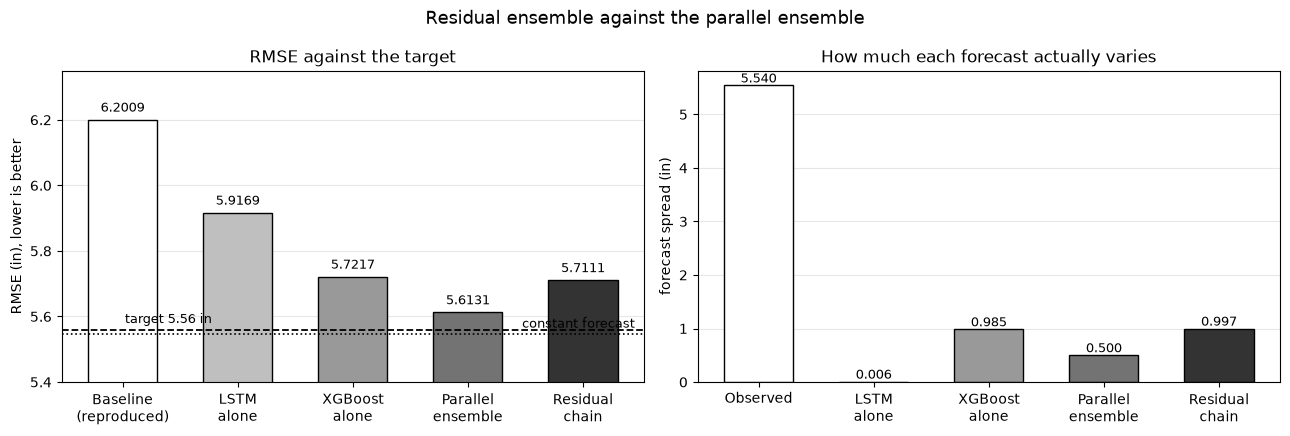

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))

ax = axes[0]
names = ['Baseline\n(reproduced)', 'LSTM\nalone', 'XGBoost\nalone', 'Parallel\nensemble',
         'Residual\nchain']
vals = [BASELINE_RMSE, lstm_eval['rmse'], xgb_eval['rmse'], par_eval['rmse'], chain_eval['rmse']]
bars = ax.bar(names, vals, color=['white', '0.75', '0.6', '0.45', '0.2'],
              edgecolor='black', width=0.6)
ax.axhline(TARGET_RMSE, color='black', ls='--', lw=1.3)
ax.text(0.02, TARGET_RMSE + 0.02, 'target 5.56 in', fontsize=9)
ax.axhline(const_eval['rmse'], color='black', ls=':', lw=1.2)
ax.text(4.45, const_eval['rmse'] + 0.02, 'constant forecast', fontsize=9, ha='right')
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.015, f'{v:.4f}', ha='center',
            va='bottom', fontsize=9, bbox=dict(fc='white', ec='none', pad=0.6))
ax.set_ylabel('RMSE (in), lower is better')
ax.set_ylim(5.4, 6.35)
ax.set_title('RMSE against the target')
ax.grid(axis='y', alpha=0.3)
ax.set_axisbelow(True)

ax = axes[1]
names2 = ['Observed', 'LSTM\nalone', 'XGBoost\nalone', 'Parallel\nensemble', 'Residual\nchain']
sds = [y_test_orig.std(), lstm_eval['pred_sd'], xgb_eval['pred_sd'], par_eval['pred_sd'],
       chain_eval['pred_sd']]
bars = ax.bar(names2, sds, color=['white', '0.75', '0.6', '0.45', '0.2'],
              edgecolor='black', width=0.6)
for b, v in zip(bars, sds):
    ax.text(b.get_x() + b.get_width() / 2, v, f'{v:.3f}', ha='center', va='bottom', fontsize=9)
ax.set_ylabel('forecast spread (in)')
ax.set_title('How much each forecast actually varies')
ax.grid(axis='y', alpha=0.3)
ax.set_axisbelow(True)

plt.suptitle('Residual ensemble against the parallel ensemble', fontsize=13)
plt.tight_layout()
plt.savefig(MODEL_DIR / 'residual_chain.png', dpi=130, bbox_inches='tight')
plt.show()

In [16]:
results = {
    'experiment': 'residual chain: LSTM first, XGBoost trained on the LSTM residuals',
    'derived_from': 'LSTM_XGB_Prefinal.ipynb',
    'what_is_held_identical': [
        'dataset and cleaning', 'box-cox lambda (loaded and asserted equal)',
        'fitted scaler (loaded)', 'split at 9058', '70-day window',
        'LSTM weights (loaded, not retrained)', 'XGBoost settings',
    ],
    'not_done_here': ['hyperparameter search', 'weight optimisation', 'booster or objective sweep'],
    'residual_space': 'box-cox',
    'xgboost_settings': {'selected': search['selected'], 'fit_strategy': search['fit_strategy'],
                         'objective': search['objective'], 'trees_used': trees_used,
                         'fit_seconds': chain_fit_seconds},
    'preprocessing': {'box_cox_lambda': float(lam_value),
                      'inverse_transform_asymptote': float(BC_UPPER),
                      'clipped_test_predictions': int(n_clipped)},
    'headroom': {
        'observed_sd_train': float(y_train_orig.std()),
        'lstm_pred_sd_train': float(lstm_train_orig.std()),
        'lstm_share_of_observed_sd_train': float(lstm_train_orig.std() / y_train_orig.std()),
        'observed_sd_test': float(y_test_orig.std()),
        'lstm_pred_sd_test': float(lstm_test_orig.std()),
        'corr_residual_observed_train': float(corr_resid),
    },
    'collapse_check': {
        'corr_chain_vs_xgboost_alone': float(corr_chain_xgb),
        'rmse_gap_vs_xgboost_alone': float(rmse_gap),
        'mean_offset_in': float(mean_offset),
    },
    'baseline_reference': {'stated': BASELINE_RMSE_STATED, 'reproduced': BASELINE_RMSE,
                           'target': TARGET_RMSE},
    'evaluation_1day': {e['label']: {k: v for k, v in e.items() if k != 'label'}
                        for e in (lstm_eval, xgb_eval, par_eval, chain_eval, const_eval)},
    'rainfall_intensity_mae': df_intensity.replace({np.nan: None}).to_dict(orient='records'),
    'n_scored_days': int(len(y_test_orig)),
}

with open(MODEL_DIR / 'metadata.json', 'w') as f:
    json.dump(results, f, indent=4, default=float)

np.savez_compressed(MODEL_DIR / 'predictions.npz', y_test_orig=y_test_orig,
                    lstm=lstm_test_orig, xgboost_alone=xgb_alone_orig,
                    parallel=parallel_orig, residual_chain=chain_pred_orig)

print(f"saved {MODEL_DIR / 'metadata.json'}")
print(f"saved {MODEL_DIR / 'predictions.npz'}")
print(f"saved {MODEL_DIR / 'residual_chain.png'}")

saved models\v2_residual_chain\metadata.json
saved models\v2_residual_chain\predictions.npz
saved models\v2_residual_chain\residual_chain.png


In [17]:
# confirm nothing outside this experiment's own directory was written
problems = []
for name, before in HASHES_ON_ENTRY.items():
    after = sha256_dir(Path(name))
    if after == before:
        print(f"{name} unchanged, all {len(after)} files match their entry hashes")
    else:
        changed = sorted({k for k in set(after) | set(before) if after.get(k) != before.get(k)})
        problems.append(f"{name}: {changed}")
if problems:
    raise RuntimeError("directories were modified: " + "; ".join(problems))
print("\nthe parallel run's artifacts were read, never written")

models\v2_static unchanged, all 4 files match their entry hashes


models\v2_prefinal unchanged, all 19 files match their entry hashes

the parallel run's artifacts were read, never written
